In [4]:
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

BASE = '/content/drive/MyDrive/battery-cycling-quality-analytics'
DATA_PROCESSED = os.path.join(BASE, 'data', 'processed')
OUTPUTS = os.path.join(BASE, 'outputs', 'charts')
os.makedirs(OUTPUTS, exist_ok=True)

full = pd.read_parquet(os.path.join(DATA_PROCESSED, 'nasa_pcoe_long.parquet'))
print(f"Loaded {len(full):,} rows across {full['cell_id'].nunique()} cells")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Loaded 2,089,050 rows across 4 cells


In [5]:
# Get all discharge cycle numbers for B0005, sorted
discharge_cycles = sorted(
    full[(full['cell_id'] == 'B0005') & (full['cycle_type'] == 'discharge')]['cycle_number'].unique()
)
print(f"B0005 has {len(discharge_cycles)} discharge cycles")
print(f"First few: {discharge_cycles[:5]}")
print(f"Last few: {discharge_cycles[-5:]}")

# Pick 4 cycles: ~5%, ~35%, ~70%, ~95% through the cell's life
n = len(discharge_cycles)
picks = [discharge_cycles[int(n * 0.05)],
         discharge_cycles[int(n * 0.35)],
         discharge_cycles[int(n * 0.70)],
         discharge_cycles[int(n * 0.95)]]
print(f"Picked cycles for overlay: {picks}")

B0005 has 168 discharge cycles
First few: [np.int64(2), np.int64(4), np.int64(6), np.int64(8), np.int64(10)]
Last few: [np.int64(600), np.int64(604), np.int64(608), np.int64(612), np.int64(614)]
Picked cycles for overlay: [np.int64(18), np.int64(194), np.int64(423), np.int64(584)]


Saved → /content/drive/MyDrive/battery-cycling-quality-analytics/outputs/charts/03_discharge_overlay_B0005.png


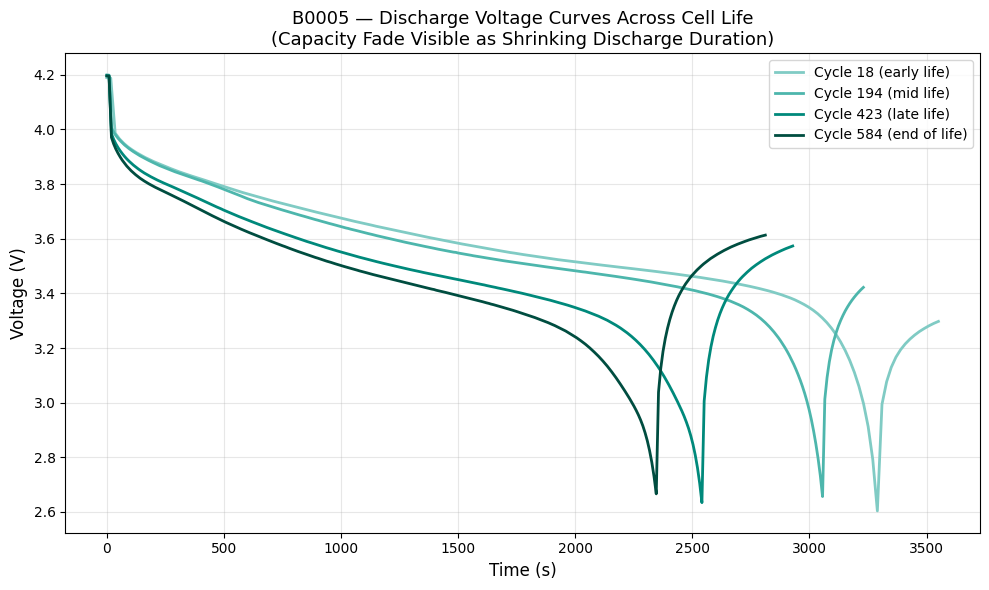

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))

# Teal gradient from light (early life) to dark (late life)
colors = ['#80cbc4', '#4db6ac', '#00897b', '#004d40']
labels_suffix = ['early life', 'mid life', 'late life', 'end of life']

for cyc, color, suffix in zip(picks, colors, labels_suffix):
    curve = full[(full['cell_id'] == 'B0005')
                 & (full['cycle_number'] == cyc)
                 & (full['cycle_type'] == 'discharge')]
    ax.plot(curve['t_s'].values, curve['V'].values,
            color=color, linewidth=2,
            label=f'Cycle {cyc} ({suffix})')

ax.set_xlabel('Time (s)', fontsize=12)
ax.set_ylabel('Voltage (V)', fontsize=12)
ax.set_title('B0005 — Discharge Voltage Curves Across Cell Life\n(Capacity Fade Visible as Shrinking Discharge Duration)',
             fontsize=13)
ax.legend(loc='upper right', frameon=True)
ax.grid(True, alpha=0.3)
plt.tight_layout()

# Save PNG for the portfolio
out_path = os.path.join(OUTPUTS, '03_discharge_overlay_B0005.png')
fig.savefig(out_path, dpi=150, bbox_inches='tight')
print(f"Saved → {out_path}")

plt.show()